# History of all rounds

The c-notebooks show the **latest** round only. This notebook keeps the record of every round: what was tried,
what it scored, and which decision it led to. Nothing here is recomputed; it reads the saved run records
(config, training history and val scores of every run) from `history/` and `results/`.

| Round | Where | Selection rule | Epoch cap | Notebooks |
|---|---|---|---|---|
| r0 | Mac (M1, MPS) | tie rule: change only if better by > 2·σ_seed·√(2/n) ≈ 5 pp, else keep simpler/default | 60 | c1 to c5 complete, c6 half, c7 started |
| r1 | desktop (RTX 2080 Ti) | tie rule (as r0) | 60 | c6 to c10 |
| r2 | desktop | highest mean val balanced accuracy wins | 60 | c5 to c10 |
| r3 | desktop | highest mean val balanced accuracy wins | 200 (early stopping, patience 20) | c5 to c10 |

Every number is val balanced accuracy on clean val (832 images), mean over seeds unless stated. The test set has
not been used in any round.

In [1]:
import json, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
pd.set_option("display.max_rows", 500, "display.max_colwidth", 80, "display.width", 200)

H = Path("history")
r3 = H / "r3_desktop_no-tie-rule_200ep"
ROUNDS = {   # round -> (results dir, artifacts dir)
    "r0": (H / "r0_mac_committed/claude_run/results", H / "r0_mac_committed/claude_run/artifacts"),
    "r1": (H / "r1_desktop_tie-rule_60ep_partial/results", None),
    "r2": (H / "r2_desktop_no-tie-rule_60ep/results", H / "r2_desktop_no-tie-rule_60ep/artifacts"),
    "r3": ((r3 / "results", r3 / "artifacts") if r3.exists() else (Path("results"), Path("artifacts"))),
}

rows = []
for rnd, (rdir, _) in ROUNDS.items():
    for f in sorted(rdir.glob("c*/*.json")):
        r = json.loads(f.read_text()); c = r["config"]; v = r["val"]
        rows.append({"round": rnd, "exp": f.parent.name, "option": re.sub(r"_s\d{4}$", "", c["name"]), "seed": c["seed"],
                     "bal_acc": v["bal_acc"], "macro_f1": v["macro_f1"], "tumor_auc": v["tumor_auc"],
                     "best_ep": r["best_epoch"], "epochs_run": r["epochs_run"], "cap": c["epochs"],
                     "params": r["n_params"], "device": r.get("device", "?")})
runs = pd.DataFrame(rows)
# A round's results folder also holds files from earlier rounds (reused from the cache, or never revisited).
# Identical records are the same training run: keep it once, under the round that trained it.
runs["key"] = runs[["exp", "option", "seed", "bal_acc", "epochs_run"]].astype(str).agg("|".join, axis=1)
runs = runs.drop_duplicates("key", keep="first").drop(columns="key")
print(f"{len(runs)} distinct training runs, by the round that trained them:", runs.groupby("round").size().to_dict())

534 distinct training runs, by the round that trained them: {'r0': 125, 'r1': 75, 'r2': 155, 'r3': 179}


## 1. Decisions per round

What each round decided at each step. r1's artifacts were overwritten by r2 before history keeping existed; its
decisions are taken from `history/r1_desktop_tie-rule_60ep_partial/RECORD.md` (copied from the r1 logs).

In [2]:
def load(art, name):
    p = art / name if art else None
    return json.loads(p.read_text()) if p and p.exists() else {}

def arch_str(a):
    if not a: return None
    return (f"{'residual' if a['residual'] else 'plain'} {1 + 4 * a['depths'][0] if a['block'] == 'single' else 1 + 8 * a['depths'][0]} layers, "
            f"{a['kernel']}x{a['kernel']}, {a['downsample']}, width {a['widths'][0]}")

def final_score(rdir):
    f = rdir / "c9" / "final_s1738.json"
    return round(json.loads(f.read_text())["val"]["bal_acc"], 4) if f.exists() else None

dec = {}
for rnd, (rdir, art) in ROUNDS.items():
    i, o, a, g, t = (load(art, n) for n in ["input.json", "optim.json", "arch.json", "reg.json", "threshold.json"])
    dec[rnd] = {"input": i and f"{i['mode']}, {i['resize']}, {i['size']} px, {i['normalize']} norm",
                "optimiser / lr": o and f"{o['optimizer']} {o['lr']:g}", "batch size": o.get("batch_size"),
                "lr schedule": o.get("schedule"), "loss": o.get("loss"),
                "small candidate": arch_str(a.get("small")), "deep candidate": arch_str(a.get("deep")),
                "winner": g.get("winner"), "augmentation": g.get("aug"), "weight decay": g.get("weight_decay"),
                "dropout": g.get("dropout"), "final model val bal. acc (seed 1738)": final_score(rdir),
                "tumour threshold": t and round(t["threshold"], 3)}
dec["r1"] = {"input": "gray, crop, 128 px, global norm", "optimiser / lr": "adam 0.03", "batch size": 32,
             "lr schedule": "none", "loss": "ce", "small candidate": "plain 5 layers, 3x3, maxpool, width 16",
             "deep candidate": "residual 17 layers, 3x3, maxpool, width 16", "winner": "small", "augmentation": "none",
             "weight decay": 0.0, "dropout": 0.0, "final model val bal. acc (seed 1738)": 0.932, "tumour threshold": 0.405}
dec["r0"]["optimiser / lr"] = dec["r0"]["optimiser / lr"] + " (c4 default; c6 unfinished on the Mac)"
D = pd.DataFrame(dec)[list(ROUNDS)].replace({"": None})
display(D)

,r0,r1,r2,r3
input,"gray, crop, 128 px, global norm","gray, crop, 128 px, global norm","gray, crop, 128 px, per_image norm","gray, crop, 128 px, per_image norm"
optimiser / lr,adam 0.001 (c4 default; c6 unfinished on the Mac),adam 0.03,adam 0.03,adam 0.03
batch size,64,32,64,128
lr schedule,none,none,none,none
loss,ce,ce,label_smoothing,focal
small candidate,None,"plain 5 layers, 3x3, maxpool, width 16","plain 5 layers, 5x5, avgpool, width 16","residual 9 layers, 5x5, avgpool, width 16"
deep candidate,None,"residual 17 layers, 3x3, maxpool, width 16","residual 17 layers, 5x5, avgpool, width 32","residual 17 layers, 5x5, avgpool, width 16"
winner,None,small,small,small
augmentation,None,none,mild,geometric
weight decay,None,0.0,0.0,0.0


## 2. Final model score per round

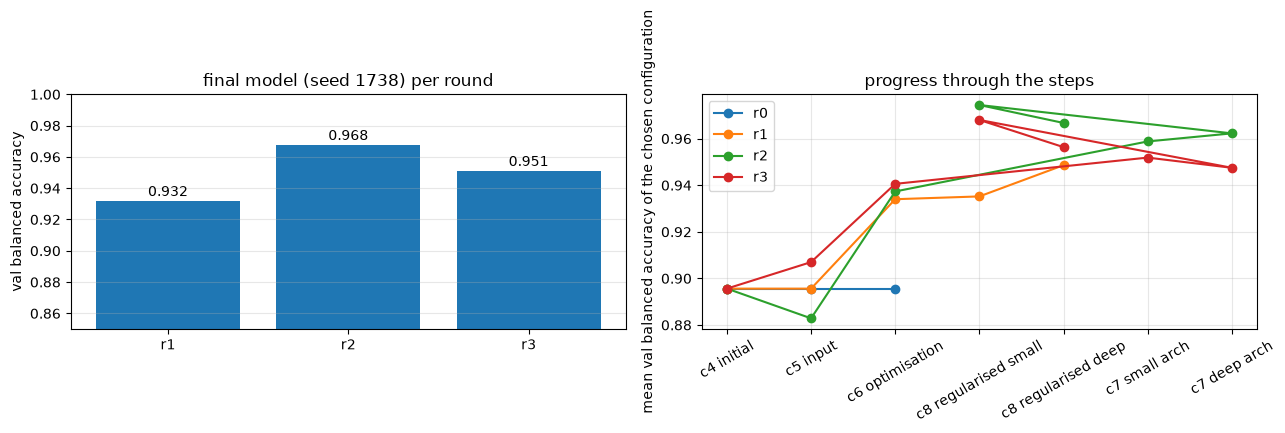

In [3]:
prog = {rnd: load(art, "progress.json") for rnd, (_, art) in ROUNDS.items()}
prog["r1"] = {"c4 initial": 0.8956, "c5 input": 0.8956, "c6 optimisation": 0.934, "c8 regularised small": 0.9352,
              "c8 regularised deep": 0.9486}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
fs = {r: D.loc["final model val bal. acc (seed 1738)", r] for r in ROUNDS}
fs = {r: v for r, v in fs.items() if v is not None and not pd.isna(v)}
ax[0].bar(list(fs), list(fs.values()), color="C0"); ax[0].set(ylim=(0.85, 1), ylabel="val balanced accuracy",
          title="final model (seed 1738) per round"); ax[0].grid(alpha=0.3, axis="y")
for k, v in fs.items(): ax[0].text(k, v + 0.003, f"{v:.3f}", ha="center")
for rnd, p in prog.items():
    if p: ax[1].plot(list(p), list(p.values()), "o-", label=rnd)
ax[1].set(ylabel="mean val balanced accuracy of the chosen configuration", title="progress through the steps")
ax[1].tick_params(axis="x", rotation=30); ax[1].grid(alpha=0.3); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Every configuration tried, per notebook

One row per configuration (run name without the seed), one column block per round: mean val balanced accuracy,
number of seeds, and the mean number of epochs actually trained. Each run is listed under the round that trained
it; a later round that reused it from the cache shows an empty cell. Run names encode the choices made earlier in
the same round, so the same question can appear under different names in different rounds (for example
`k3s3_maxpool_plain17` in r1 and `k5s5_avgpool_plain17` in r2).

In [4]:
agg = (runs.groupby(["exp", "option", "round"])
           .agg(bal_acc=("bal_acc", "mean"), sd=("bal_acc", "std"), n=("seed", "size"), epochs=("epochs_run", "mean"))
           .round(4).reset_index())
for exp in sorted(agg.exp.unique()):
    t = agg[agg.exp == exp].pivot(index="option", columns="round", values=["bal_acc", "n", "epochs"])
    t = t.swaplevel(axis=1).sort_index(axis=1, level=0)
    display(Markdown(f"### {exp}"))
    display(t)

### c4

round          r0            
          bal_acc epochs    n
option                       
long       0.8817   60.0  5.0
overfit64  0.6104  150.0  1.0
seed       0.8892   54.4  5.0

### c5

round              r0                    r2                  r3              
              bal_acc   epochs    n bal_acc epochs    n bal_acc   epochs    n
option                                                                       
crop              NaN      NaN  NaN     NaN    NaN  NaN  0.8949  75.0000  3.0
input_choice      NaN      NaN  NaN  0.8828   47.0  3.0  0.9070  62.3333  3.0
pad            0.9031  49.0000  3.0     NaN    NaN  NaN  0.9118  81.0000  3.0
perimage       0.9006  51.0000  3.0     NaN    NaN  NaN  0.9038  52.3333  3.0
probe_crop     0.7381  44.3333  3.0     NaN    NaN  NaN  0.7461  40.3333  3.0
probe_pad      0.7872  48.3333  3.0     NaN    NaN  NaN  0.8050  44.6667  3.0
probe_stretch  0.7968  40.3333  3.0     NaN    NaN  NaN  0.7927  43.6667  3.0
r192           0.8457  42.3333  3.0     NaN    NaN  NaN  0.8798  47.6667  3.0
r64            0.8855  48.0000  3.0     NaN    NaN  NaN  0.8917  57.0000  3.0
rgb            0.8772  50.0000  3.0     NaN    NaN  NaN  0.8870  52.0000  3.0
stretch        0.8818  39.6667  3.0     NaN    NaN  NaN  0.8815  44.0000  3.0

### c6

round                               r0                    r1                    r2                    r3              
                               bal_acc   epochs    n bal_acc   epochs    n bal_acc   epochs    n bal_acc   epochs    n
option                                                                                                                
adam_lr0.0001                   0.8557  60.0000  3.0     NaN      NaN  NaN  0.8778  60.0000  3.0  0.8833  83.6667  3.0
adam_lr0.0003                   0.8716  55.3333  3.0     NaN      NaN  NaN  0.8920  48.3333  3.0  0.8909  72.3333  3.0
adam_lr0.001_bs128              0.8912  60.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.001_bs32               0.8674  43.3333  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.001_bs64_cosine        0.8998  56.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.001_bs64_none_focal    0.8950  56.6667  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.001_bs64_none_ls       0.8820  48.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.001_bs64_none_sampler  0.8741  48.6667  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.001_bs64_none_wce      0.9034  60.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.001_bs64_plateau       0.8911  52.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.001_bs64_step          0.8980  57.3333  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.003                    0.9133  56.6667  3.0     NaN      NaN  NaN  0.9112  45.6667  3.0  0.8898  58.3333  3.0
adam_lr0.01                     0.9218  59.0000  3.0     NaN      NaN  NaN  0.9209  54.6667  3.0  0.9137  52.3333  3.0
adam_lr0.03                     0.9275  60.0000  3.0     NaN      NaN  NaN  0.9371  55.0000  3.0  0.9359  64.3333  3.0
adam_lr0.03_bs128               0.9162  59.0000  3.0     NaN      NaN  NaN  0.9223  50.6667  3.0  0.9381  68.0000  3.0
adam_lr0.03_bs128_cosine           NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN  0.9133  55.3333  3.0
adam_lr0.03_bs128_none_focal       NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN  0.9406  77.3333  3.0
adam_lr0.03_bs128_none_ls          NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN  0.9309  51.6667  3.0
adam_lr0.03_bs128_none_sampler     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN  0.9347  70.0000  3.0
adam_lr0.03_bs128_none_wce         NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN  0.9368  87.3333  3.0
adam_lr0.03_bs128_plateau          NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN  0.9324  46.0000  3.0
adam_lr0.03_bs128_step             NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN  0.9292  62.6667  3.0
adam_lr0.03_bs32                0.9340  60.0000  3.0     NaN      NaN  NaN  0.9305  58.0000  3.0  0.9350  71.0000  3.0
adam_lr0.03_bs32_cosine         0.9316  59.6667  3.0     NaN      NaN  NaN     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.03_bs32_none_focal        NaN      NaN  NaN  0.9221  60.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.03_bs32_none_ls           NaN      NaN  NaN  0.9369  50.6667  3.0     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.03_bs32_none_sampler      NaN      NaN  NaN  0.9235  60.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.03_bs32_none_wce          NaN      NaN  NaN  0.9340  55.6667  3.0     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.03_bs32_plateau           NaN      NaN  NaN  0.9319  45.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.03_bs32_step              NaN      NaN  NaN  0.9389  60.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN
adam_lr0.03_bs64_cosine            NaN      NaN  NaN     NaN      NaN  Na

... (4 outputs left out)

### c8

round                              r1                    r2                    r3              
                              bal_acc   epochs    n bal_acc   epochs    n bal_acc   epochs    n
option                                                                                         
deep_aug_geometric                NaN      NaN  NaN  0.9611  60.0000  2.0  0.9330  49.0000  2.0
deep_aug_geometric_wd0.01         NaN      NaN  NaN  0.9504  55.5000  2.0     NaN      NaN  NaN
deep_aug_geometric_wd0.1          NaN      NaN  NaN  0.8584  39.0000  2.0     NaN      NaN  NaN
deep_aug_geometric_wd0_do0.3      NaN      NaN  NaN  0.9667  60.0000  2.0     NaN      NaN  NaN
deep_aug_mild                     NaN      NaN  NaN  0.9610  54.0000  2.0  0.9534  72.5000  2.0
deep_aug_none                     NaN      NaN  NaN  0.9602  58.5000  2.0  0.9564  86.5000  2.0
deep_aug_none_wd0.01           0.9343  60.0000  2.0     NaN      NaN  NaN  0.9535  74.5000  2.0
deep_aug_none_wd0.1            0.7825  30.5000  2.0     NaN      NaN  NaN  0.8677  54.0000  2.0
deep_aug_none_wd0_do0.3        0.9532  52.0000  2.0     NaN      NaN  NaN  0.9442  87.5000  2.0
deep_aug_strong                   NaN      NaN  NaN  0.9585  60.0000  2.0  0.9463  64.5000  2.0
small_aug_geometric               NaN      NaN  NaN  0.9680  60.0000  3.0  0.9680  76.6667  3.0
small_aug_geometric_wd0.01        NaN      NaN  NaN     NaN      NaN  NaN  0.9524  76.3333  3.0
small_aug_geometric_wd0.1         NaN      NaN  NaN     NaN      NaN  NaN  0.8786  50.6667  3.0
small_aug_geometric_wd0_do0.3     NaN      NaN  NaN     NaN      NaN  NaN  0.9591  94.3333  3.0
small_aug_mild                    NaN      NaN  NaN  0.9744  59.3333  3.0  0.9639  93.0000  3.0
small_aug_mild_wd0.01             NaN      NaN  NaN  0.9525  58.6667  3.0     NaN      NaN  NaN
small_aug_mild_wd0.1              NaN      NaN  NaN  0.8266  43.3333  3.0     NaN      NaN  NaN
small_aug_mild_wd0_do0.3          NaN      NaN  NaN  0.9632  60.0000  3.0     NaN      NaN  NaN
small_aug_none                    NaN      NaN  NaN  0.9572  49.6667  3.0  0.9505  57.0000  3.0
small_aug_none_wd0.01          0.8953  52.3333  3.0     NaN      NaN  NaN     NaN      NaN  NaN
small_aug_none_wd0.1           0.7602  33.6667  3.0     NaN      NaN  NaN     NaN      NaN  NaN
small_aug_none_wd0_do0.3       0.9218  55.0000  3.0     NaN      NaN  NaN     NaN      NaN  NaN
small_aug_strong                  NaN      NaN  NaN  0.9591  60.0000  3.0  0.9612  90.0000  3.0

### c9

round             r2                  r3              
             bal_acc epochs    n bal_acc   epochs    n
option                                                
final         0.9685   60.0  3.0  0.9521  55.3333  3.0
final_lr0.01     NaN    NaN  NaN  0.9598  73.3333  3.0
lr0.01        0.9649   60.0  3.0  0.9601  81.0000  3.0
lr0.09        0.9520   60.0  3.0  0.9391  60.3333  3.0

## 4. Round records (decisions, outcomes and observations written per round)

In [5]:
for rec in sorted(H.glob("r*/RECORD.md")):
    display(Markdown(rec.read_text(encoding="utf-8")))

# Round r1: first desktop run (RTX 2080 Ti), old tie rule, 60-epoch cap

Run on 2026-11-12, 11:01 to 12:55, notebooks c6 to c10 (c4 and c5 from the Mac, round r0).

Selection rule in this round: an option replaced the current choice only if its 3-seed mean val balanced accuracy
beat the baseline by more than 2 * sigma_seed * sqrt(2/n), with sigma_seed = 0.0309 measured in c4 on the weak
lr 1e-3 model. With n = 3 that is 0.0505 (0.0619 for 2 vs 2 seeds). Otherwise "tie", and the simpler or default
option was kept. Sweeps (lr, batch size) fell back to the default unless a trend/peak fit was significant.

Why this file exists: the executed notebooks and logs of r1 were overwritten by round r2 before history keeping
was in place, and so were the result files whose run names r2 reused. 150 result files of r1 survive in
`results/` next to this file. The tables below were copied from the r1 logs during the session.

Input (from c5, r0): gray, crop to head, 128 px, global normalisation.

## c6 optimisation

Device check (c4 baseline, 3 seeds each): MPS 0.8956 (sd 0.0088), CUDA 0.8973 (sd 0.0095): tie, 3.80 vs 0.55 s/epoch.

Adam learning rate (3 seeds each, val balanced accuracy). These runs were not retrained in r1: they are the Mac
(r0) runs, reused from the cache (about 4 s/epoch, the MPS speed). r1 retrained only what the Mac had not run.

| lr | bal_acc | sd |
|---|---|---|
| 1e-4 | 0.8557 | 0.0076 |
| 3e-4 | 0.8716 | 0.0107 |
| 1e-3 (baseline) | 0.8956 | 0.0088 |
| 3e-3 | 0.9133 | 0.0052 |
| 1e-2 | 0.9218 | 0.0178 |
| 3e-2 | 0.9275 | 0.0042 |
| 1e-1 | 0.8954 | 0.0110 |

Trend fit: slope +1.83 pp/decade (95% CI 0.96 to 2.70), p_linear 0.0003, peak inside the range. Chosen lr 0.03.

Decisions: optimiser Adam 0.03 (vs SGD), batch size 32, schedule none, loss cross-entropy.
Result: {optimizer adam, lr 0.03, batch 32, schedule none, loss ce, sampler none}, mean val bal. acc 0.934.

## c7 architecture

| question | option | bal_acc | delta | verdict |
|---|---|---|---|---|
| kernel | 3x3 (baseline) | 0.9230 | 0 | |
| | 5x5 | 0.9432 | +0.0202 | tie |
| | 7x7 stem + 3x3 | 0.9139 | -0.0090 | tie |
| downsampling | maxpool (baseline) | 0.9230 | 0 | |
| | avgpool | 0.9312 | +0.0082 | tie |
| | stride | 0.8684 | -0.0546 | worse |
| depth | plain 5 (baseline) | 0.9230 | 0 | |
| | plain 9 | 0.9281 | +0.0052 | tie |
| | plain 17 | 0.8723 | -0.0507 | worse |
| | plain 33 | 0.8467 | -0.0762 | worse |
| | residual 9 | 0.9519 | +0.0289 | tie |
| | residual 17 | 0.9502 | +0.0273 | tie |
| | residual 33 | 0.9330 | +0.0100 | tie |
| | plain 5 / plain 17 / residual 17, no BatchNorm | 0.2500 | -0.6730 | worse (collapsed at epoch 1, lr 0.03 diverges without BN) |
| width (residual 17) | 16 (baseline) | 0.9502 | 0 | |
| | 32 | 0.9554 | +0.0052 | tie |

Decisions: 3x3 kernels, maxpool, width 16. Candidates for c8: small = plain 5, deep = residual 17 (width 16).

## c8 regularisation

Augmentation (val balanced accuracy, train-val gap in brackets):

| aug | small (3 seeds) | deep (2 seeds) |
|---|---|---|
| none (baseline) | 0.9352 (gap 0.061) | 0.9486 (gap 0.045) |
| geometric | 0.9469 (gap 0.020) | 0.9668 (gap 0.014) |
| mild | 0.9436 (gap 0.017) | 0.9646 (gap 0.009) |
| strong | 0.9352 (gap -0.010) | 0.9585 (gap -0.001) |

All ties under the rule. Decisions: augmentation none, weight decay 0, dropout 0 for both models;
winner small (deep not "clearly better").

## c9 final model

Learning-rate re-check kept 0.03. Final model: 5 conv layers, 100,244 parameters, 0.6 s/epoch.
Seed 1738 (fixed in advance) on clean val: balanced accuracy 0.932 [95% CI 0.913, 0.949].
Mean over 3 seeds 0.930.

(c9 first failed with `TypeError: replace() got multiple values for keyword argument 'optimizer'`;
fixed in make_c9.py by merging the settings into one dict, then rerun.)

## c10 threshold

Threshold for tumour sensitivity >= 0.98 on clean val: 0.405, balanced accuracy 0.9336. Test set not evaluated.

## Outcome

The rule's bar (0.05) was larger than any effect in c6 to c8 (observed seed sd 0.004 to 0.009), so it kept the
baseline almost everywhere. This led to round r2, where the option with the highest mean wins.


# Round r2: desktop (RTX 2080 Ti), highest mean wins, 60-epoch cap

Run on 2026-11-12, 18:19 to 21:32, notebooks c5 to c10. Complete record next to this file: `results/`,
`artifacts/`, the executed notebooks and `logs/`.

Rule: the option with the highest mean val balanced accuracy wins, whatever its size or cost. Sweeps take the
value with the highest mean (trend fits reported, not gating). One validity guard kept in c5: among geometries
within 2 standard errors of the best, take the one with the least signal outside the head (shortcut probe).
c7 width sweep extended with width 64 (skipped on the Mac for speed).

## Decisions and outcomes

| step | decision | mean val bal. acc |
|---|---|---|
| c5 input | gray, crop, 128 px, **per-image normalisation** | 0.883 (CUDA retrain of the choice) |
| c6 optimisation | Adam 0.03, batch 64, no schedule, **label smoothing** | 0.937 |
| c7 architecture | **5x5 kernels, avgpool**; deep = residual 17 at **width 32** (16: 0.9555, 32: 0.9623, 64: 0.9594) | small 0.959, deep 0.962 |
| c8 regularisation | small: **mild augmentation**, wd 0, dropout 0; deep: geometric aug, wd 0, dropout 0.3 | small 0.974, deep 0.967 |
| c8 winner | **small** (277k parameters) over deep (7.7M) on mean score | 0.974 |
| c9 final | lr re-check kept 0.03; seed 1738: **0.968 [95% CI 0.955, 0.979]**; accuracy 0.966, macro-F1 0.966 | |
| c10 threshold | 0.717 for tumour sensitivity >= 0.98; balanced accuracy 0.967 | |

## Observations

* **Cross-device comparison in c5.** Per-image normalisation was chosen from the Mac runs (MPS, 0.901) against
  global (0.896, also MPS). Retrained on CUDA in c6 the same per-image configuration scored 0.883. The c5 choice
  therefore rested on a cross-device comparison and is not supported by the CUDA runs. Round r3 retrains every
  c5 option on CUDA.
* Most runs reached their best epoch near the 60-epoch cap (augmented runs were still improving), which led to
  round r3 with a 200-epoch cap and early stopping.


# Round r3: desktop (RTX 2080 Ti), highest mean wins, 200-epoch cap with early stopping

Run on 2026-11-12 21:54 to 2026-11-13 01:46, notebooks c5 to c10. Complete record next to this file:
`results/`, `artifacts/`, the executed notebooks and `logs/`. Runs that r3 replaced are also kept in
`claude_run/results/_superseded/` (304 files from r2).

Changes from r2: epoch cap raised from 60 to 200 from c5 on (`EPOCH_CAP` in `lib/report.py`); early stopping
unchanged (patience 20 on val balanced accuracy, best weights restored). c4 left untouched; c5 trains its own
baseline (`c5/crop`) instead of reusing c4's 60-epoch runs. Every c5 option retrained on CUDA.
Side effect: cosine and step LR schedules are sized to 200 epochs, so early stopping can end them before the
LR has decayed; they are at a disadvantage in c6.

## Decisions and outcomes

| step | decision | mean val bal. acc |
|---|---|---|
| c5 input | gray, crop, 128 px, per-image normalisation (crop baseline 0.895, pad 0.912 but more shortcut signal) | 0.907 |
| c6 optimisation | Adam 0.03, **batch 128**, no schedule, **focal loss** | 0.941 |
| c7 architecture | 5x5 kernels, avgpool; small = **residual 9**, deep = residual 17 at **width 16** (16: 0.9475, 32: 0.9475, 64: 0.9452; exact tie, first option kept) | small 0.952, deep 0.947 |
| c8 regularisation | small: **geometric augmentation**, wd 0, dropout 0; deep: no augmentation, wd 0, dropout 0 | small 0.968, deep 0.956 |
| c8 winner | small (residual 9, 832k parameters) | 0.968 |
| c9 lr re-check | **0.01** (0.9601) over 0.03 (0.9521) and 0.09 (0.9391) | |
| c9 final | seeds 1738 / 1739 / 1740: 0.952 / 0.959 / 0.968 (mean 0.960); seed 1738 **0.952 [95% CI 0.935, 0.966]** | |
| c10 threshold | 0.710 for tumour sensitivity >= 0.98; balanced accuracy 0.957, tumour AUC 0.997 | |

## Observations

* **The longer cap did not improve the result.** Runs used the room (77 to 87 epochs on average in c8 instead
  of the 60 cap), but the final model scored 0.952 against r2's 0.968, and the best c8 configuration 0.968
  against r2's 0.974. The confidence intervals overlap: r2 and r3 are about equal, not r3 worse.
* **Several step winners changed between r2 and r3** (batch size 64 to 128, label smoothing to focal loss, plain 5
  to residual 9, mild to geometric augmentation, final lr 0.03 to 0.01). These options lie within seed noise of
  each other, so which one "wins" a step partly depends on chance; the path through the steps then differs.
* The seed chosen in advance as the final model (1738) was the weakest of the three in r3 (0.952 vs 0.959, 0.968).
* **Why early stopping did not prevent the worse result.** Early stopping works inside one run: it ends training
  when val stops improving and restores the best epoch, so a run can never end worse than its own best epoch.
  Checked on all 188 r3 runs: the best val score within the first 60 epochs averaged 0.8822, the best overall
  0.8842 (+0.19 pp; 20 % of runs improved after epoch 60, none got worse). So the longer cap made each run
  slightly better, not worse. What it cannot do is stop the selection from taking a different path: r3's steps
  chose different (within-noise) winners than r2, ended at a different final configuration, and the final seed
  fixed in advance happened to be that configuration's weakest. The lower score comes from the selection path
  and seed noise, not from training too long.
* Best performer across all rounds remains the r2 final model (`history/best_model/r2_final_s1738.pt`).
  r3's weights were not kept.


## 5. Every single run

In [6]:
display(runs.sort_values(["round", "exp", "option", "seed"]).reset_index(drop=True).round(4))

,round,exp,option,seed,bal_acc,macro_f1,tumor_auc,best_ep,epochs_run,cap,params,device
0,r0,c4,long,1738,0.8977,0.8965,0.9895,54,60,60,100244,mps
1,r0,c4,long,1739,0.8735,0.8781,0.9912,47,60,60,100244,mps
2,r0,c4,long,1740,0.8663,0.8671,0.9909,31,60,60,100244,mps
3,r0,c4,long,1741,0.8723,0.8764,0.9903,37,60,60,100244,mps
4,r0,c4,long,1742,0.8986,0.8965,0.9950,52,60,60,100244,mps
...,...,...,...,...,...,...,...,...,...,...,...,...
529,r3,c9,lr0.01,1739,0.9662,0.9602,0.9974,96,116,200,832308,cuda
530,r3,c9,lr0.01,1740,0.9560,0.9530,0.9951,52,72,200,832308,cuda
531,r3,c9,lr0.09,1738,0.9475,0.9396,0.9937,59,79,200,832308,cuda
532,r3,c9,lr0.09,1739,0.9388,0.9303,0.9954,26,46,200,832308,cuda
